# Multichannel NMF demo: two sources, two microphones, reverberant room

This notebook simulates a stereo reverberant mixture of a voice and an accompaniment, fits the
multichannel NMF model of Ozerov & Févotte (2010) with EM, and separates the source spatial images
by multichannel Wiener filtering.

Required files (see the README, section *Data*):
- `data/vocals_mono.wav`, `data/guitar_mono.wav`: 15 s mono excerpts at 44.1 kHz (MUSDB18 stems).
- `data/AIR_1_4/air_binaural_aula_carolina_{0,1}_1_3_{45,135}_3.mat`: binaural RIRs from the AIR database.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # batched 2x2 inversions are faster single-threaded

import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf

from mnmf.em import fit
from mnmf.metrics import best_permutation_sdr
from mnmf.mixing import load_air_rir, spatial_images
from mnmf.separation import source_images_stft
from mnmf.stft import istft, stft

## 1. Simulate the mixture

Each source is placed at a different azimuth (45° and 135°) of the binaural head in the Aula Carolina
hall; channel 1 is the left ear (microphone 0) and channel 0 the right ear (microphone 1).

In [2]:
SR = 44100
DATA = "../data"

vocals, _ = sf.read(f"{DATA}/vocals_mono.wav")
guitar, _ = sf.read(f"{DATA}/guitar_mono.wav")


def rir(channel, azimuth):
    """Load the Aula Carolina RIR for one ear and one source azimuth."""
    return load_air_rir(f"{DATA}/AIR_1_4/air_binaural_aula_carolina_{channel}_1_3_{azimuth}_3.mat", SR)


images = spatial_images([vocals, guitar], [[rir(1, 45), rir(0, 45)], [rir(1, 135), rir(0, 135)]])
mixture = images.sum(axis=0)
sf.write(f"{DATA}/mixture.wav", mixture.T, SR)
print("images", images.shape, "mixture", mixture.shape)

images (2, 2, 661500) mixture (2, 661500)


## 2. Fit the model with EM

Two sources with four NMF components each, STFT window of 2048 samples (46 ms) with 50 % overlap.

X (1025, 647, 2)


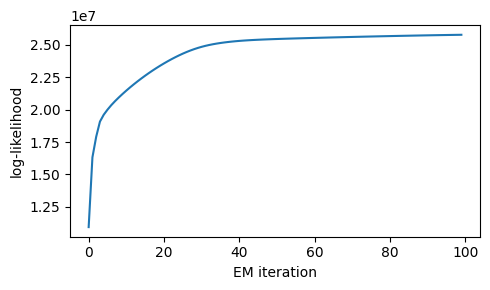

In [3]:
N_FFT = 2048
X = stft(mixture, N_FFT)
params, labels, log_liks = fit(X, n_sources=2, n_components=4, n_iter=100, seed=0)
print("X", X.shape)

plt.figure(figsize=(5, 3))
plt.plot(log_liks)
plt.xlabel("EM iteration")
plt.ylabel("log-likelihood")
plt.tight_layout()
plt.show()

## 3. Separate and evaluate

The estimated order of the sources is arbitrary; it is matched to the references by maximising the mean
SDR. The SDR is the plain energy ratio between the reference image and the estimation error (no BSS Eval
projections). The mixture itself, used as the estimate of every source, gives the baseline.

In [4]:
Y = source_images_stft(X, params, labels)
estimates = np.stack([istft(Yj, N_FFT, mixture.shape[1]) for Yj in Y])

sdr_est, order = best_permutation_sdr(images, estimates)
sdr_mix, _ = best_permutation_sdr(images, np.stack([mixture, mixture]))
for name, j in zip(["vocals", "accompaniment"], range(2)):
    print(f"{name:14s} SDR mixture {sdr_mix[j]:6.2f} dB | SDR estimate {sdr_est[j]:6.2f} dB")

for j, k in enumerate(order):
    sf.write(f"{DATA}/estimate_{j}.wav", estimates[k].T, SR)

vocals         SDR mixture   2.37 dB | SDR estimate   3.34 dB
accompaniment  SDR mixture  -2.37 dB | SDR estimate  -0.52 dB


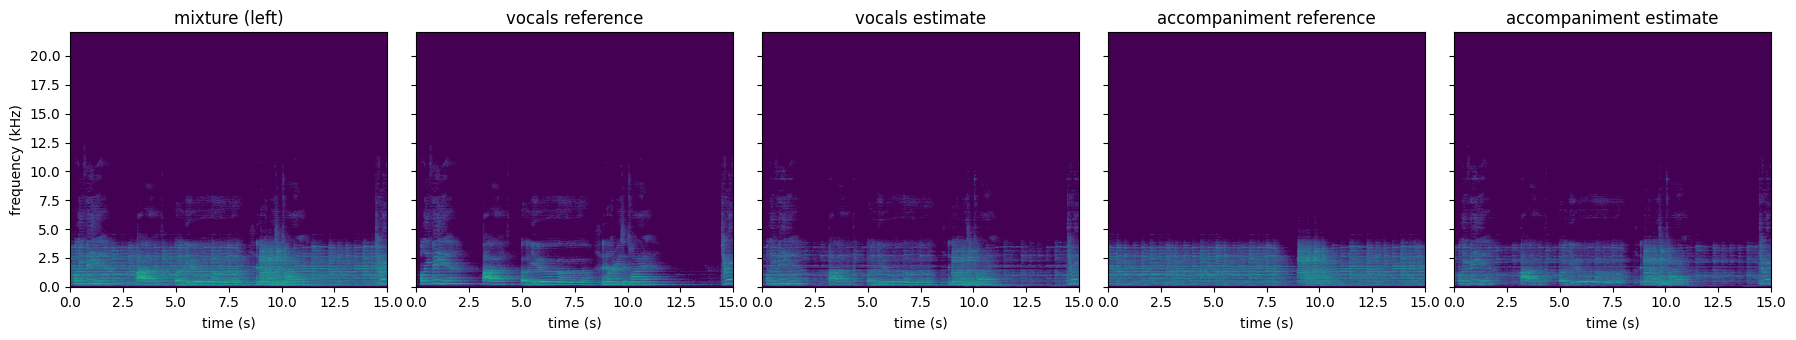

In [5]:
def log_spec(x):
    """Return the log-magnitude STFT (dB) of a mono signal."""
    return 20 * np.log10(np.abs(stft(x[None], N_FFT)[..., 0]) + 1e-6)


titles = ["mixture (left)", "vocals reference", "vocals estimate", "accompaniment reference", "accompaniment estimate"]
signals = [mixture[0], images[0, 0], estimates[order[0], 0], images[1, 0], estimates[order[1], 0]]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for ax, title, x in zip(axes, titles, signals):
    ax.imshow(log_spec(x), origin="lower", aspect="auto", vmin=-80, vmax=0,
              extent=[0, len(x) / SR, 0, SR / 2000])
    ax.set_title(title)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("frequency (kHz)")
plt.tight_layout()
plt.savefig("../figures/spectrograms.png", dpi=100)
plt.show()